# 第097讲可执行实验

先阅读lecture.md与lab.md，再重启内核从上到下执行。所有数据本地合成；不调用网络、GPU或付费模型。输出会覆盖本讲可再生的outputs/figures；探索实验请复制目录。

## 1 核对环境与工作目录
Notebook依赖同目录experiment.py。不要只下载.ipynb。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
ROOT = Path.cwd()
assert (ROOT / "experiment.py").exists(), "请切换到本讲目录"
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)

Python: 3.12.14 NumPy: 2.3.5


## 2 阅读实现并形成预测
下面列出核心实验源码。先对照讲义找出数据生成、模型或解析场、积分与评价四个位置。代码内注释解释形状、方向与边界。

In [2]:
import inspect
import experiment
print(inspect.getsource(experiment))

"""原创 CPU 教学实验。运行 python experiment.py；无需网络、GPU 或模型下载。"""
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/dl-mpl")
import json, time
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
ROOT = Path(__file__).resolve().parent
OUT = ROOT / "outputs"
FIG = ROOT / "figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=160); plt.close()

def generate(z,noise_seed,steps,kind):
    # 同一标准正态 z 用于各方法/步数的起点，降低起点抽样混杂。
    mu=2.;v0=.36;T=4.;h=T/steps;x=mu+np.sqrt(v0+T)*z
    rng=np.random.default_rng(noise_seed);start=time.perf_counter()
    for k in range(steps):
        t=T-k*h;score=-(x-mu)/(v0+t)
        if kind=='sde':x+=h*score+np.sqrt(h)*rng.normal(size=len(x))
        else:x+=.5*h*score
    return x,time.perf_counter()-start

def main():
    records=[];arrays={};target_mu=2.;target_std=.6
    for seed in (11,23,37,51,73):
        z=np.random.defa

## 3 从头重新运行实验
这会真实生成样本、计算指标并重建图形；不是展示缓存结果。

In [3]:
results = experiment.main()

{
  "paired_summary": [
    {
      "steps": 10,
      "paired_difference_mean": 0.10816073546758842,
      "paired_difference_se": 0.005467376311778142
    },
    {
      "steps": 40,
      "paired_difference_mean": 0.024422048195230243,
      "paired_difference_se": 0.006496788308349289
    },
    {
      "steps": 160,
      "paired_difference_mean": 0.0028767801562861605,
      "paired_difference_se": 0.005895289347424871
    }
  ]
}


## 4 核对持久化证据
先看每个数组的形状与是否有限，再解释指标。

In [4]:
saved = json.loads((ROOT / "outputs/metrics.json").read_text())
print(json.dumps(saved, ensure_ascii=False, indent=2))
with np.load(ROOT / "outputs/data.npz") as data:
    for key in data.files:
        a = data[key]
        print(key, a.shape, "finite:", bool(np.isfinite(a).all()))

{
  "protocol": "fixed before evaluation; analytic score; no model training",
  "records": [
    {
      "seed": 11,
      "steps": 10,
      "method": "sde",
      "n": 4000,
      "nfe": 10,
      "seconds": 0.00081457699980092,
      "mean": 1.9732813643440636,
      "std": 0.7850250600331654,
      "moment_distance": 0.18694426530811567,
      "central_95_coverage": 0.86425
    },
    {
      "seed": 11,
      "steps": 10,
      "method": "ode",
      "n": 4000,
      "nfe": 10,
      "seconds": 9.106800007430138e-05,
      "mean": 2.008018190001717,
      "std": 0.6776091976111509,
      "moment_distance": 0.07802229761260755,
      "central_95_coverage": 0.9195
    },
    {
      "seed": 11,
      "steps": 40,
      "method": "sde",
      "n": 4000,
      "nfe": 40,
      "seconds": 0.0037740470002063375,
      "mean": 2.0083909284621,
      "std": 0.6419669818484999,
      "moment_distance": 0.04279760794633737,
      "central_95_coverage": 0.936
    },
    {
      "seed": 11,
 

## 5 看完整图，不挑漂亮样本
图与讲义对应。观察不符合直觉的地方，结合指标解释。

01_quality.png


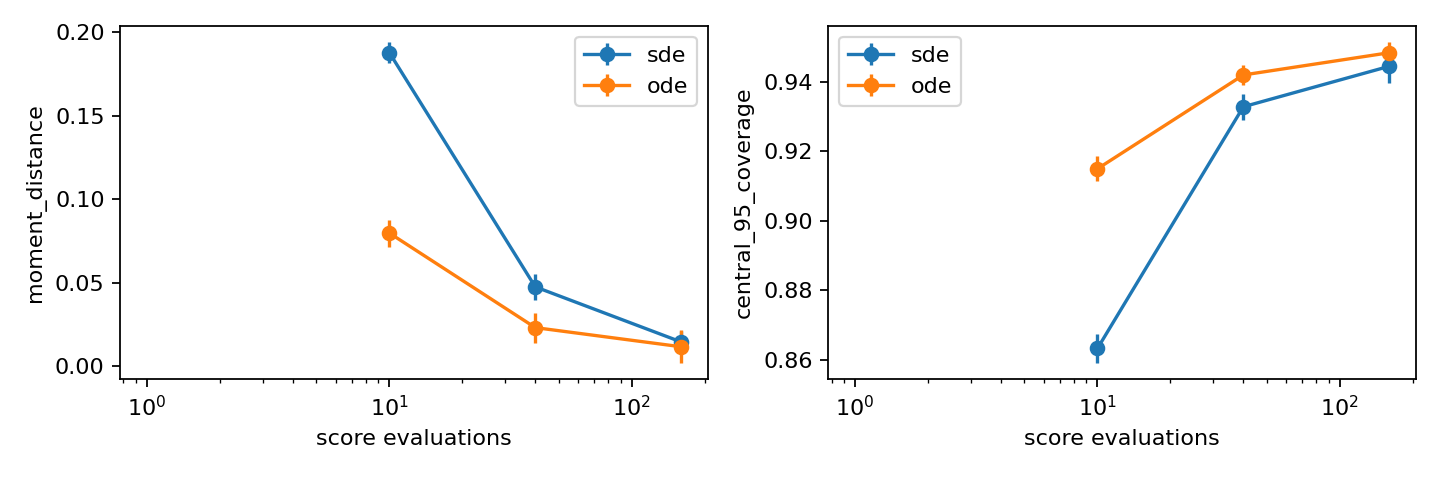

02_cost.png


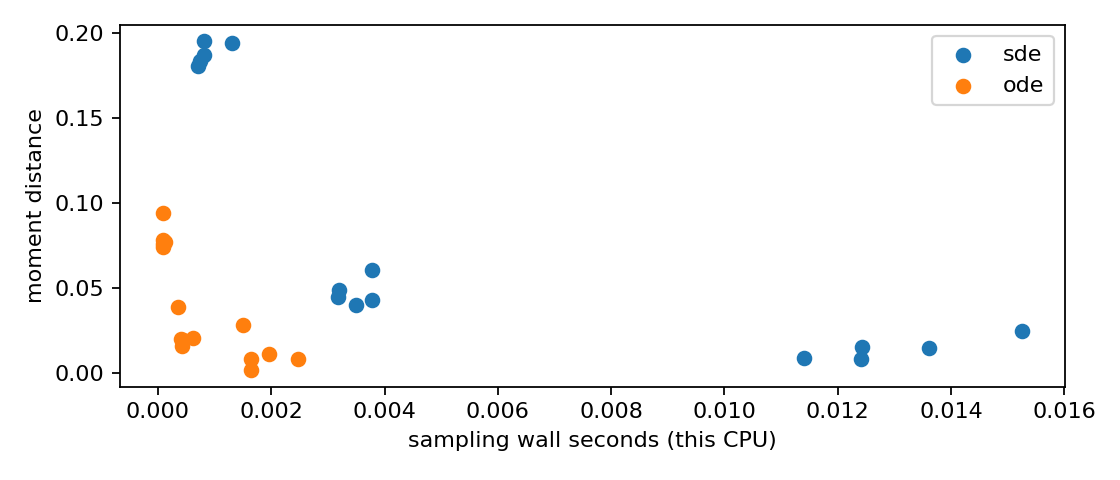

03_distribution.png


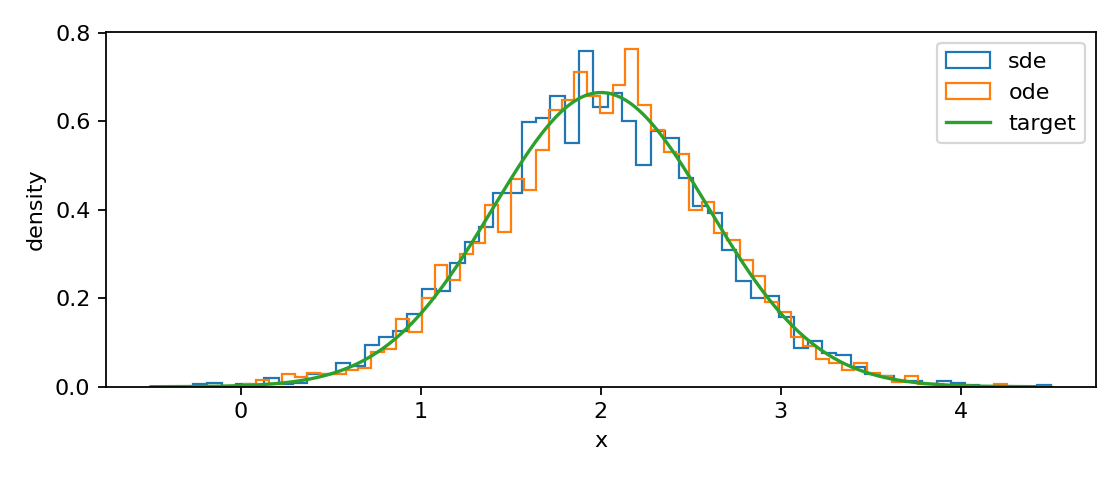

In [5]:
from IPython.display import display, Image
for figure in sorted((ROOT / "figures").glob("*.png")):
    print(figure.name)
    display(Image(filename=str(figure), width=760))

## 6 执行独立断言
测试通过只覆盖这些明确断言，不等于现实部署验证。之后按lab.md做一个受控变化。

In [6]:
import unittest
import tests
suite = unittest.defaultTestLoader.loadTestsFromModule(tests)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()

test_exact_center (tests.TestExperiment.test_exact_center) ... 

ok


test_ode_deterministic (tests.TestExperiment.test_ode_deterministic) ... 

ok


test_pairing (tests.TestExperiment.test_pairing) ... 

...

test_recalculate_metric (tests.TestExperiment.test_recalculate_metric) ... 

ok


test_records (tests.TestExperiment.test_records) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.015s

OK


## 反思与交付
写清本实验是学习模型还是解析score、样本数和种子、主要误差来源、实际结果与未检验范围。练习详解见answers.md。